<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/30_expansion/33_expansion_moran_lisa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 33 · Moran global y LISA del uso agropecuario por celda

**Autor:** Daniel

**Pregunta (sección 11.2 de la ruta):** ¿el uso agropecuario y su expansión están agrupados en el espacio, y dónde están los focos de expansión?

**Entradas:**
- `datos/comunes/grilla_2km.gpkg` (cuaderno 02, DVC).
- `datos/comunes/agro_celda.csv` (cuaderno 30, DVC).
- `datos/comunes/altillanura_municipios.gpkg` (cuaderno 01, DVC), solo para los mapas.

**Salidas** (en `modulos/expansion/resultados/` y `modulos/expansion/graficas/`):
- `33_moran_global.csv`, `33_lisa_conteos.csv`, `33_alto_alto_municipio.csv`, `33_correlograma.csv`.
- `33_lisa_celdas.csv` (DVC): una fila por celda con su cuadrante LISA.
- `33_lisa_agro.png`, `33_correlograma.png`.

**Método:**
- Variables: (a) % agropecuario 2024 (`agro_pct_2024`) y (b) cambio 2000–2024 (`cambio_agro_pp`), en las celdas válidas del cuaderno 30.
- Vecindad reina (queen) de la grilla de 2 km: las 8 celdas que tocan a cada celda. Pesos estandarizados por fila. Es la misma vecindad del cuaderno 61.
- **I de Moran global** con 999 permutaciones. I > 0 significa que celdas vecinas se parecen (agrupamiento). Con 999 permutaciones el menor valor p posible es 0,001, así que ese caso se reporta como p ≤ 0,001.
- **LISA** (Moran local) con 999 permutaciones. Como se hace una prueba por celda (más de 30.000), la significancia se corrige por pruebas múltiples con la **tasa de falsos descubrimientos (FDR) del 5 %** de Benjamini–Hochberg (`esda.fdr`). Los conteos sin corrección (p < 0,05 y p < 0,01) quedan solo como referencia. Las celdas **alto–alto** son celdas altas rodeadas de celdas altas: en el cambio 2000–2024 son los focos de expansión.
- **Correlograma de Moran**: I por anillos de distancia de 4 km hasta 60 km, en una muestra de 4.000 celdas, para ver hasta qué distancia llega el agrupamiento.
- Con solo 7 municipios, el Moran municipal no tiene potencia, así que no se calcula.

## Paso 1. Rutas y librerías
- En **Colab** clona el repo en `/content/Proyecto-ALTILLANURA`.
- En **local** toma como raíz la carpeta del repo (dos niveles arriba del cuaderno).
- `traer(ruta)` baja de DVC un archivo cuando hace falta.

In [1]:
import os, sys, re, glob, subprocess, warnings
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))

COMUNES = os.path.join(RAIZ, 'datos', 'comunes')
EXPANSION = os.path.join(RAIZ, 'modulos', 'expansion')
CRUDOS = os.path.join(EXPANSION, 'datos', 'mapbiomas_crudos')
RESULTADOS = os.path.join(EXPANSION, 'resultados')
GRAFICAS = os.path.join(EXPANSION, 'graficas')
os.makedirs(RESULTADOS, exist_ok=True)
os.makedirs(GRAFICAS, exist_ok=True)

def traer(ruta):
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

def coma(valor, decimales=1):
    return f'{valor:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
import esda
import libpysal

SEMILLA = 2026
PERMUTACIONES = 999
ALFA = 0.05
P_MINIMO = 1 / (PERMUTACIONES + 1)
VARIABLES = {'agro_pct_2024': '% agropecuario 2024', 'cambio_agro_pp': 'cambio 2000–2024 (pp)'}

print('Raíz del repo:', RAIZ)
print('esda', esda.__version__, '| libpysal', libpysal.__version__)

Raíz del repo: c:\Users\mipip\Downloads\altillanura_proyecto_\altillanura_proyecto
esda 2.9.0 | libpysal 4.14.1


c:\Users\mipip\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Paso 2. Datos y vecindad reina
Las coordenadas de cada celda salen de su `id_celda` (esquina inferior izquierda en km). Dos celdas son vecinas si están a 2 km en x, en y o en diagonal. Las celdas que quedan sin vecinas (islas) se quitan.

In [2]:
traer('datos/comunes/grilla_2km.gpkg')
traer('datos/comunes/agro_celda.csv')
traer('datos/comunes/altillanura_municipios.gpkg')

grilla = gpd.read_file(os.path.join(COMUNES, 'grilla_2km.gpkg')).to_crs(9377)
agro = pd.read_csv(os.path.join(COMUNES, 'agro_celda.csv'))
mpios = gpd.read_file(os.path.join(COMUNES, 'altillanura_municipios.gpkg')).to_crs(9377)

d = grilla.merge(agro, on='id_celda', how='inner')
d = d[d['celda_valida'].astype(bool)].dropna(subset=list(VARIABLES)).reset_index(drop=True)
partes = d['id_celda'].str.extract(r'x(\d+)_y(\d+)').astype(int)
d['x_km'], d['y_km'] = partes[0], partes[1]

pos = {(x, y): k for k, (x, y) in enumerate(zip(d['x_km'], d['y_km']))}
vecinos = {k: [pos[(x + dx, y + dy)] for dx in (-2, 0, 2) for dy in (-2, 0, 2)
               if (dx or dy) and (x + dx, y + dy) in pos]
           for (x, y), k in pos.items()}
islas = [k for k, v in vecinos.items() if not v]
if islas:
    d = d.drop(index=islas).reset_index(drop=True)
    pos = {(x, y): k for k, (x, y) in enumerate(zip(d['x_km'], d['y_km']))}
    vecinos = {k: [pos[(x + dx, y + dy)] for dx in (-2, 0, 2) for dy in (-2, 0, 2)
                   if (dx or dy) and (x + dx, y + dy) in pos]
               for (x, y), k in pos.items()}

w = libpysal.weights.W(vecinos, silence_warnings=True)
w.transform = 'r'
print(f'Celdas válidas: {len(d):,} de {len(grilla):,} | islas quitadas: {len(islas)} | vecinas promedio: {w.mean_neighbors:.1f}')

Celdas válidas: 34,473 de 34,763 | islas quitadas: 0 | vecinas promedio: 7.9


## Paso 3. I de Moran global

In [3]:
def texto_p(p):
    return f'p ≤ {coma(P_MINIMO, 3)}' if p <= P_MINIMO + 1e-12 else f'p = {coma(p, 3)}'

np.random.seed(SEMILLA)
filas = []
for variable, etiqueta in VARIABLES.items():
    m = esda.Moran(d[variable].to_numpy(dtype=float), w, permutations=PERMUTACIONES)
    filas.append({'variable': variable, 'descripcion': etiqueta, 'n_celdas': len(d), 'I_moran': m.I,
                  'I_esperado': m.EI, 'p_permutacion': m.p_sim, 'p_minimo_posible': P_MINIMO,
                  'p_reporte': texto_p(m.p_sim), 'permutaciones': PERMUTACIONES})
moran_global = pd.DataFrame(filas)
moran_global.round(5).to_csv(os.path.join(RESULTADOS, '33_moran_global.csv'), index=False)
print(moran_global.round(4).to_string(index=False))

      variable           descripcion  n_celdas  I_moran  I_esperado  p_permutacion  p_minimo_posible p_reporte  permutaciones
 agro_pct_2024   % agropecuario 2024     34473   0.7936        -0.0          0.001             0.001 p ≤ 0,001            999
cambio_agro_pp cambio 2000–2024 (pp)     34473   0.6019        -0.0          0.001             0.001 p ≤ 0,001            999


## Paso 4. LISA: dónde están los grupos
Se hace una prueba por celda, así que con p < 0,05 sin corregir saldrían muchas celdas significativas por azar. Por eso una celda cuenta como significativa solo si pasa la **FDR del 5 %** (Benjamini–Hochberg, con `esda.fdr`), que da un umbral de p para cada variable. Cada celda significativa cae en un cuadrante:
- **Alto–alto**: valor alto rodeado de valores altos.
- **Bajo–bajo**: valor bajo rodeado de valores bajos.
- **Alto–bajo** y **bajo–alto**: celdas atípicas frente a sus vecinas.

La tabla `33_lisa_conteos.csv` compara los conteos con la FDR y sin corrección (p < 0,05 y p < 0,01). El mapa, la tabla por municipio y el resumen usan la FDR.

In [4]:
ETIQUETAS = {1: 'Alto–alto', 2: 'Bajo–alto', 3: 'Bajo–bajo', 4: 'Alto–bajo'}
ORDEN_ETIQUETAS = ['Alto–alto', 'Bajo–bajo', 'Alto–bajo', 'Bajo–alto', 'No significativo']

def cuadrantes(local, significativa):
    return pd.Series(np.where(significativa, local.q, 0)).map(ETIQUETAS).fillna('No significativo').to_numpy()

lisa = pd.DataFrame({'id_celda': d['id_celda'], 'mpio_cdpmp': d['mpio_cdpmp'], 'municipio': d['mpio_cnmbr']})
UMBRAL_FDR = {}
conteos = []
for variable in VARIABLES:
    local = esda.Moran_Local(d[variable].to_numpy(dtype=float), w, permutations=PERMUTACIONES, seed=SEMILLA)
    UMBRAL_FDR[variable] = float(esda.fdr(local.p_sim, ALFA))
    criterios = {'FDR 5 %': (UMBRAL_FDR[variable], local.p_sim < UMBRAL_FDR[variable]),
                 'p < 0,05 sin corrección': (0.05, local.p_sim < 0.05),
                 'p < 0,01 sin corrección': (0.01, local.p_sim < 0.01)}
    for criterio, (umbral, significativa) in criterios.items():
        conteo = pd.Series(cuadrantes(local, significativa)).value_counts()
        conteos.append({'variable': variable, 'criterio': criterio, 'umbral_p': umbral,
                        **{e: int(conteo.get(e, 0)) for e in ORDEN_ETIQUETAS}})
    lisa[f'lisa_{variable}'] = cuadrantes(local, criterios['FDR 5 %'][1])
    lisa[f'p_{variable}'] = local.p_sim
conteos = pd.DataFrame(conteos)
conteos.round(5).to_csv(os.path.join(RESULTADOS, '33_lisa_conteos.csv'), index=False)
lisa.round(4).to_csv(os.path.join(RESULTADOS, '33_lisa_celdas.csv'), index=False)
print(conteos.round(5).to_string(index=False))

columna = 'lisa_cambio_agro_pp'
por_mpio = (lisa.assign(alto_alto=lisa[columna] == 'Alto–alto')
            .groupby('municipio').agg(celdas=('id_celda', 'size'), alto_alto=('alto_alto', 'sum')))
por_mpio['pct_alto_alto'] = por_mpio['alto_alto'] / por_mpio['celdas'] * 100
por_mpio['pct_del_total_alto_alto'] = por_mpio['alto_alto'] / max(por_mpio['alto_alto'].sum(), 1) * 100
por_mpio['pct_de_las_celdas'] = por_mpio['celdas'] / por_mpio['celdas'].sum() * 100
por_mpio = por_mpio.sort_values('alto_alto', ascending=False)
por_mpio.round(2).to_csv(os.path.join(RESULTADOS, '33_alto_alto_municipio.csv'))
print('\nFocos de expansión (alto–alto del cambio 2000–2024, FDR 5 %) por municipio:')
print(por_mpio.round(1).to_string())

primeros = por_mpio.index[:2]
PRIMEROS = ' y '.join(n.title() for n in primeros)
PCT_PRIMEROS = por_mpio['pct_del_total_alto_alto'].iloc[:2].sum()
TASA = por_mpio['pct_alto_alto'].idxmax()
GRANDE = por_mpio['celdas'].idxmax()

      variable                criterio  umbral_p  Alto–alto  Bajo–bajo  Alto–bajo  Bajo–alto  No significativo
 agro_pct_2024                 FDR 5 %   0.02507       4498      12592         14        184             17185
 agro_pct_2024 p < 0,05 sin corrección   0.05000       5071      14258         23        308             14813
 agro_pct_2024 p < 0,01 sin corrección   0.01000       3677      10902          4         65             19825
cambio_agro_pp                 FDR 5 %   0.00454       2125        823         55        128             31342
cambio_agro_pp p < 0,05 sin corrección   0.05000       4135      11805        187        560             17786
cambio_agro_pp p < 0,01 sin corrección   0.01000       2691       1513         79        219             29971

Focos de expansión (alto–alto del cambio 2000–2024, FDR 5 %) por municipio:
                celdas  alto_alto  pct_alto_alto  pct_del_total_alto_alto  pct_de_las_celdas
municipio                                            

## Paso 5. Mapas de clústeres LISA

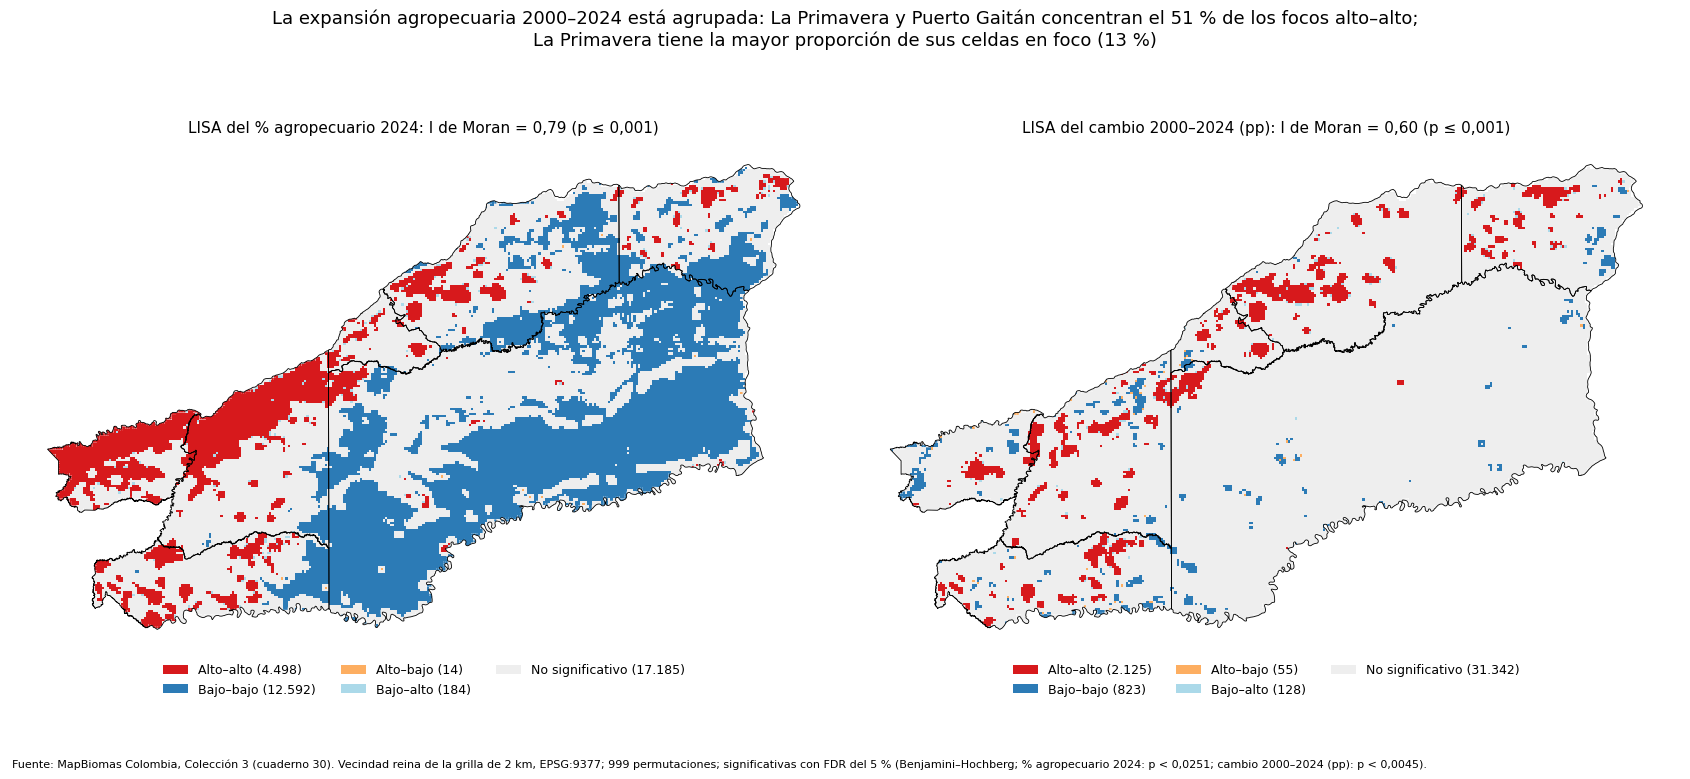

In [5]:
COLORES = {'Alto–alto': '#d7191c', 'Bajo–bajo': '#2c7bb6', 'Alto–bajo': '#fdae61',
           'Bajo–alto': '#abd9e9', 'No significativo': '#eeeeee'}
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
for ax, variable in zip(axes, VARIABLES):
    for etiqueta, color in COLORES.items():
        sub = d[lisa[f'lisa_{variable}'].to_numpy() == etiqueta]
        if len(sub):
            sub.plot(ax=ax, color=color, linewidth=0, label=f'{etiqueta} ({coma(len(sub), 0)})')
    mpios.boundary.plot(ax=ax, color='black', linewidth=0.6)
    fila = moran_global.set_index('variable').loc[variable]
    ax.set_title(f'LISA del {VARIABLES[variable]}: I de Moran = {coma(fila.I_moran, 2)} ({texto_p(fila.p_permutacion)})', fontsize=11)
    ax.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False)
    ax.set_axis_off()
fig.suptitle(f'La expansión agropecuaria 2000–2024 está agrupada: {PRIMEROS} concentran el {coma(PCT_PRIMEROS, 0)} % de los focos alto–alto;\n'
             f'{TASA.title()} tiene la mayor proporción de sus celdas en foco ({coma(por_mpio.loc[TASA, "pct_alto_alto"], 0)} %)', fontsize=13)
umbrales = '; '.join(f'{VARIABLES[v]}: p < {coma(u, 4)}' for v, u in UMBRAL_FDR.items())
fig.text(0.01, -0.03, 'Fuente: MapBiomas Colombia, Colección 3 (cuaderno 30). Vecindad reina de la grilla de 2 km, EPSG:9377; '
         f'999 permutaciones; significativas con FDR del 5 % (Benjamini–Hochberg; {umbrales}).', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '33_lisa_agro.png'), dpi=150, bbox_inches='tight')
plt.show()

## Paso 6. Correlograma de Moran por distancia
I de Moran con pesos binarios por anillos de 4 km (0–4, 4–8, …, 56–60 km) en una muestra aleatoria de 4.000 celdas válidas. El valor p de cada anillo sale de 199 permutaciones de los valores entre las celdas de la muestra. Donde la curva cruza el valor esperado (≈ 0) termina el agrupamiento.

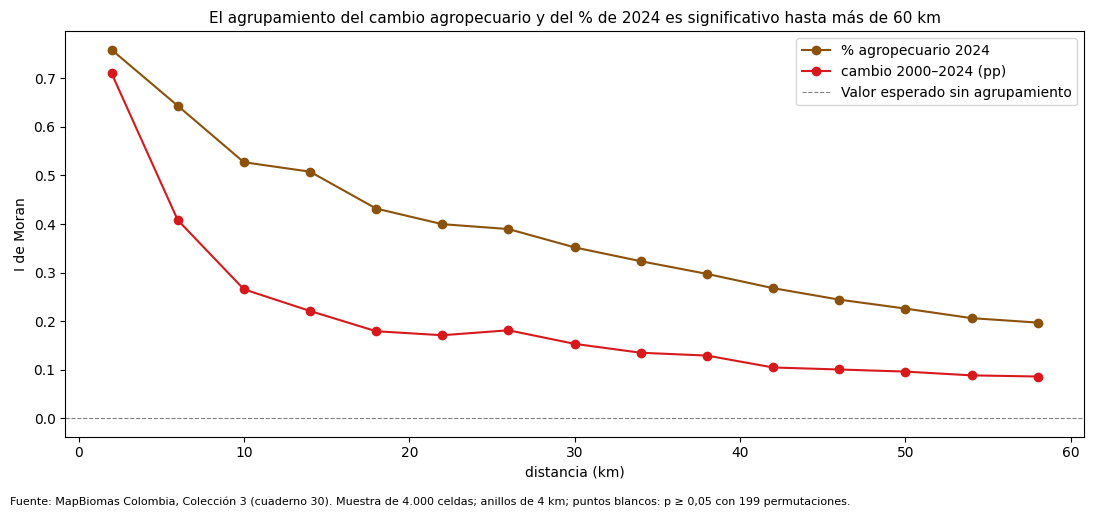

In [6]:
ANILLO_KM = 4
MAX_KM = 60
PERMUTACIONES_ANILLO = 199
rng = np.random.default_rng(SEMILLA)
m = min(4000, len(d))
muestra = rng.choice(len(d), m, replace=False)
xy = d[['x_km', 'y_km']].to_numpy(dtype=float)[muestra] + 1.0
pares = cKDTree(xy).query_pairs(MAX_KM, output_type='ndarray')
i, j = pares[:, 0], pares[:, 1]
anillo = np.minimum((np.hypot(*(xy[i] - xy[j]).T) // ANILLO_KM).astype(int), MAX_KM // ANILLO_KM - 1)
n_anillos = MAX_KM // ANILLO_KM
pares_por_anillo = np.bincount(anillo, minlength=n_anillos)

def moran_anillos(z):
    suma = np.bincount(anillo, weights=z[i] * z[j], minlength=n_anillos)
    return np.divide(m * suma, pares_por_anillo * (z @ z), out=np.full(n_anillos, np.nan), where=pares_por_anillo > 0)

filas = []
for variable in VARIABLES:
    v = d[variable].to_numpy(dtype=float)[muestra]
    z = v - v.mean()
    observado = moran_anillos(z)
    simulados = np.array([moran_anillos(rng.permutation(z)) for _ in range(PERMUTACIONES_ANILLO)])
    mayores = (np.abs(simulados) >= np.abs(observado)).sum(axis=0)
    p = (mayores + 1) / (PERMUTACIONES_ANILLO + 1)
    for k in range(n_anillos):
        filas.append({'variable': variable, 'desde_km': k * ANILLO_KM, 'hasta_km': (k + 1) * ANILLO_KM,
                      'pares': int(pares_por_anillo[k]), 'I_moran': observado[k], 'p_permutacion': p[k]})
correlograma = pd.DataFrame(filas)
correlograma.round(5).to_csv(os.path.join(RESULTADOS, '33_correlograma.csv'), index=False)

fig, ax = plt.subplots(figsize=(11, 5))
alcance = {}
for variable, color in zip(VARIABLES, ('#8c510a', '#d7191c')):
    t = correlograma[correlograma['variable'] == variable]
    centro = (t['desde_km'] + t['hasta_km']) / 2
    ax.plot(centro, t['I_moran'], color=color, marker='o', label=VARIABLES[variable])
    no_sig = t['p_permutacion'] >= ALFA
    ax.scatter(centro[no_sig], t.loc[no_sig, 'I_moran'], s=70, facecolors='white', edgecolors=color, zorder=3)
    seguidos = ((t['I_moran'] > 0) & (t['p_permutacion'] < ALFA)).to_numpy()
    k = len(seguidos) if seguidos.all() else int(np.argmin(seguidos))
    if k == len(seguidos):
        alcance[variable] = f'más de {MAX_KM} km'
    elif k == 0:
        alcance[variable] = 'menos de 4 km'
    else:
        alcance[variable] = f'unos {int(t["hasta_km"].iloc[k - 1])} km'
ax.axhline(-1 / (m - 1), color='grey', linestyle='--', linewidth=0.8, label='Valor esperado sin agrupamiento')
ax.set_xlabel('distancia (km)')
ax.set_ylabel('I de Moran')
ax.legend()
if alcance['cambio_agro_pp'] == alcance['agro_pct_2024']:
    titulo = f'El agrupamiento del cambio agropecuario y del % de 2024 es significativo hasta {alcance["cambio_agro_pp"]}'
else:
    titulo = (f'El agrupamiento del cambio agropecuario es significativo hasta {alcance["cambio_agro_pp"]} '
              f'(y el del % de 2024 hasta {alcance["agro_pct_2024"]})')
ax.set_title(titulo, fontsize=11)
fig.text(0.01, -0.02, f'Fuente: MapBiomas Colombia, Colección 3 (cuaderno 30). Muestra de {coma(m, 0)} celdas; anillos de {ANILLO_KM} km; '
         f'puntos blancos: p ≥ 0,05 con {PERMUTACIONES_ANILLO} permutaciones.', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '33_correlograma.png'), dpi=150, bbox_inches='tight')
plt.show()

## Límites
- LISA hace una prueba por celda. La FDR del 5 % controla la proporción esperada de falsos positivos entre las celdas significativas, pero no garantiza que cada celda sea un foco real; los conteos sin corrección quedan solo como referencia en `33_lisa_conteos.csv`.
- Con 999 permutaciones, el valor p más pequeño posible es 0,001; por eso el I de Moran global se reporta con p ≤ 0,001.
- El resultado depende de la vecindad elegida (reina de 2 km). El correlograma muestra cómo cambia el agrupamiento con la distancia.
- Si el correlograma sigue siendo significativo a 60 km, eso refleja en buena parte el contraste regional entre zonas con mucho y con poco uso agropecuario, y no solo focos locales.
- El cambio 2000–2024 compara dos años; no dice cuándo ocurrió la expansión dentro del periodo.
- El uso agropecuario incluye el mosaico de agricultura y pastos, así que mezcla cultivos y ganadería.

## Resumen para el informe

In [7]:
for _, f in moran_global.iterrows():
    print(f'{f.descripcion}: I de Moran = {coma(f.I_moran, 3)} ({texto_p(f.p_permutacion)}, '
          f'{PERMUTACIONES} permutaciones, {coma(f.n_celdas, 0)} celdas).')
c = conteos[conteos['variable'] == 'cambio_agro_pp'].set_index('criterio')['Alto–alto']
print(f'Focos de expansión (alto–alto del cambio 2000–2024): {coma(c["FDR 5 %"], 0)} celdas con FDR del 5 % '
      f'(umbral p < {coma(UMBRAL_FDR["cambio_agro_pp"], 4)}); sin corrección serían {coma(c["p < 0,05 sin corrección"], 0)} con p < 0,05 '
      f'y {coma(c["p < 0,01 sin corrección"], 0)} con p < 0,01.')
print(f'{PRIMEROS} concentran el {coma(PCT_PRIMEROS)} % de los focos. Por proporción de sus celdas en foco, el primero es '
      f'{TASA.title()} ({coma(por_mpio.loc[TASA, "pct_alto_alto"])} %). {GRANDE.title()} tiene el {coma(por_mpio.loc[GRANDE, "pct_de_las_celdas"])} % '
      f'de las celdas, pero el {coma(por_mpio.loc[GRANDE, "pct_del_total_alto_alto"])} % de los focos.')
print('Por municipio:', '; '.join(f'{n.title()}: {coma(r.alto_alto, 0)} focos ({coma(r.pct_del_total_alto_alto)} % del total, '
                                  f'{coma(r.pct_alto_alto)} % de sus celdas)' for n, r in por_mpio.iterrows()))
print(f'Alcance del agrupamiento (correlograma): cambio hasta {alcance["cambio_agro_pp"]}; % de 2024 hasta {alcance["agro_pct_2024"]}.')

% agropecuario 2024: I de Moran = 0,794 (p ≤ 0,001, 999 permutaciones, 34.473 celdas).
cambio 2000–2024 (pp): I de Moran = 0,602 (p ≤ 0,001, 999 permutaciones, 34.473 celdas).
Focos de expansión (alto–alto del cambio 2000–2024): 2.125 celdas con FDR del 5 % (umbral p < 0,0045); sin corrección serían 4.135 con p < 0,05 y 2.691 con p < 0,01.
La Primavera y Puerto Gaitán concentran el 51,3 % de los focos. Por proporción de sus celdas en foco, el primero es La Primavera (13,0 %). Cumaribo tiene el 48,0 % de las celdas, pero el 5,9 % de los focos.
Por municipio: La Primavera: 607 focos (28,6 % del total, 13,0 % de sus celdas); Puerto Gaitán: 484 focos (22,8 % del total, 11,0 % de sus celdas); Mapiripán: 342 focos (16,1 % del total, 10,9 % de sus celdas); Puerto Carreño: 313 focos (14,7 % del total, 10,5 % de sus celdas); Puerto López: 132 focos (6,2 % del total, 7,2 % de sus celdas); Cumaribo: 125 focos (5,9 % del total, 0,8 % de sus celdas); Santa Rosalía: 122 focos (5,7 % del total, 13,0 